# QF620 Project — Part A: Events and timing

**Goal:** for each of the 24 headlines in the events file, find when the market *actually* reacted, and how big the move was.

Files needed in the same folder as this notebook:
- `RTH.zip` and `ETH.zip` (the notebook unzips them itself)
- `2025 Liberation Day Tariff Main Events.csv`

All times are New York time.

In [1]:
import glob
import os
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

## Step 1. Check every assets file before using it

We only need the `*_assets.csv` files (SPX, ES futures bid/ask, VIX). The option files are for Parts B and C.

First, unzip RTH.zip and ETH.zip if that hasn't been done yet.

In [2]:
for name in ["RTH", "ETH"]:
    if not os.path.isdir(name):
        zipfile.ZipFile(name + ".zip").extractall()

os.listdir()

['2025 Liberation Day Tariff Main Events.csv',
 'ETH',
 'ETH.zip',
 'PartA_events_and_timing.ipynb',
 'Project (2026-27 T1).pdf',
 'RTH',
 'RTH.zip']

In [3]:
rth_files =\
    sorted(glob.glob("RTH/**/*_assets.csv", recursive = True))

rth_files

['RTH\\2025-04-01_assets.csv',
 'RTH\\2025-04-02_assets.csv',
 'RTH\\2025-04-03_assets.csv',
 'RTH\\2025-04-04_assets.csv',
 'RTH\\2025-04-07_assets.csv',
 'RTH\\2025-04-08_assets.csv',
 'RTH\\2025-04-09_assets.csv',
 'RTH\\2025-04-10_assets.csv']

In [4]:
eth_files =\
    sorted(glob.glob("ETH/**/*_assets.csv", recursive = True))

eth_files

['ETH\\2025-04-01_assets.csv',
 'ETH\\2025-04-02_assets.csv',
 'ETH\\2025-04-03_assets.csv',
 'ETH\\2025-04-06_assets.csv',
 'ETH\\2025-04-07_assets.csv',
 'ETH\\2025-04-08_assets.csv',
 'ETH\\2025-04-09_assets.csv',
 'ETH\\2025-04-10_assets.csv']

In [5]:
coverage = []

for path in rth_files + eth_files:
    df = pd.read_csv(path, index_col = 0, parse_dates = True)
    coverage.append({"file": path,
                     "rows": len(df),
                     "first_time": df.index.min(),
                     "last_time": df.index.max()})

coverage =\
    pd.DataFrame(coverage)

coverage

,file,rows,first_time,last_time
0,RTH\2025-04-01_assets.csv,7980,2025-04-01 09:31:21.491248,2025-04-01 16:14:59.562027
1,RTH\2025-04-02_assets.csv,7974,2025-04-02 09:31:21.159704,2025-04-02 16:14:58.986619
2,RTH\2025-04-03_assets.csv,7985,2025-04-03 09:31:21.894935,2025-04-03 16:14:58.001314
3,RTH\2025-04-04_assets.csv,8000,2025-04-04 09:31:22.319733,2025-04-04 16:14:58.332187
4,RTH\2025-04-07_assets.csv,7856,2025-04-07 09:31:22.249966,2025-04-07 16:14:58.413707
5,RTH\2025-04-08_assets.csv,7979,2025-04-08 09:31:21.315630,2025-04-08 16:14:58.647143
6,RTH\2025-04-09_assets.csv,7906,2025-04-09 09:31:21.769198,2025-04-09 16:14:59.882106
7,RTH\2025-04-10_assets.csv,7476,2025-04-10 09:57:17.981945,2025-04-10 16:14:58.217903
8,ETH\2025-04-01_assets.csv,15401,2025-04-01 20:15:21.924268,2025-04-02 09:14:59.033416
9,ETH\2025-04-02_assets.csv,15378,2025-04-02 20:15:22.952683,2025-04-03 09:14:58.967998


What this table tells us:
- RTH files run **09:31 → 16:15**. ETH files run **20:15 → 09:15 the next morning**.
- So every day we have **no data from 16:15 to 20:15**, and none from 09:15 to 09:31.
- `ETH/2025-04-09_assets.csv` is **empty**: there is no data for the night of Apr 9 → 10 (right after the real pause).
- There is no ETH file for Apr 4 (Friday night): the market is shut over the weekend. The `2025-04-06` ETH file is Sunday night.
- RTH on Apr 10 starts at 09:57, not 09:31.

In [6]:
def read_assets(path, session):
    df =\
    (
        pd
        .read_csv(path,
                  index_col = 0,
                  parse_dates = True)
        .assign(session = session)
    )
    return df

In [7]:
frames = []

for path in rth_files:
    df = read_assets(path, "RTH")
    if len(df) > 0:
        frames.append(df)

for path in eth_files:
    df = read_assets(path, "ETH")
    if len(df) > 0:              # skips the empty Apr 9 ETH file
        frames.append(df)

len(frames)

15

In [8]:
assets =\
(
    pd
    .concat(frames)
    .sort_index()
)

assets

,SPX,ES_BID,ES_ASK,VIX,session
2025-04-01 09:31:21.491248,5590.320,5631.75,5632.00,22.66,RTH
2025-04-01 09:31:24.535800,5590.700,5631.75,5632.00,22.66,RTH
2025-04-01 09:31:27.582698,5589.060,5629.50,5629.75,22.66,RTH
2025-04-01 09:31:30.632772,5588.660,5630.50,5630.75,22.66,RTH
2025-04-01 09:31:33.638817,5588.820,5629.75,5630.00,22.69,RTH
...,...,...,...,...,...
2025-04-11 09:14:46.807862,5243.925,5277.75,5278.00,44.77,ETH
2025-04-11 09:14:49.846746,5244.425,5278.25,5278.50,44.77,ETH
2025-04-11 09:14:52.887237,5242.300,5276.00,5276.50,44.77,ETH
2025-04-11 09:14:55.934802,5242.550,5276.25,5276.75,44.77,ETH


## Step 2. Futures mid price

Futures mid = (ES bid + ES ask) / 2

In [9]:
assets =\
(
    assets
    .assign(es_mid = lambda x: (x["ES_BID"] + x["ES_ASK"]) / 2)
)

assets[["SPX", "ES_BID", "ES_ASK", "es_mid", "VIX"]].head()

,SPX,ES_BID,ES_ASK,es_mid,VIX
2025-04-01 09:31:21.491248,5590.32,5631.75,5632.00,5631.875,22.66
2025-04-01 09:31:24.535800,5590.70,5631.75,5632.00,5631.875,22.66
2025-04-01 09:31:27.582698,5589.06,5629.50,5629.75,5629.625,22.66
2025-04-01 09:31:30.632772,5588.66,5630.50,5630.75,5630.625,22.66
2025-04-01 09:31:33.638817,5588.82,5629.75,5630.00,5629.875,22.69


**Is the SPX column real at night?** The S&P 500 index is only calculated during the day.
If the overnight SPX is just the futures price minus a fixed number, then the gap (futures − SPX) will not move at all.

In [10]:
basis_check =\
(
    assets
    .assign(basis = lambda x: x["es_mid"] - x["SPX"],
            day = lambda x: x.index.date)
    .groupby(["session", "day"])["basis"]
    .agg(["mean", "std"])
    .round(2)
)

basis_check

mean     std
session day                       
ETH     2025-04-01   41.43    0.00
        2025-04-02   41.39    0.07
        2025-04-03   39.82    2.29
        2025-04-04   36.23    0.00
        2025-04-06 -286.27    0.00
        2025-04-07 -193.13  145.77
        2025-04-08   35.71    1.12
        2025-04-09   37.48    0.00
        2025-04-10   33.95    0.00
        2025-04-11   33.95    0.00
RTH     2025-04-01   42.81    0.69
        2025-04-02   42.62    2.34
        2025-04-03   39.38    0.79
        2025-04-04   35.14    2.13
        2025-04-07   34.91    6.40
        2025-04-08   33.81    2.09
        2025-04-09   34.07    3.46
        2025-04-10   35.68    2.48

In ETH the std of the gap is **0.00** on most nights: overnight SPX is just the futures price shifted by a constant, not a real index value.
On Sunday Apr 6 the gap is about −286 points, which means the SPX column was stale.
**So we use ES futures for all timing work, day and night.**

## Step 3. One-minute prices and returns

Rows come every ~3 seconds. One-minute bars are enough to time a headline and are easier to read.

In [11]:
es_1min =\
(
    assets["es_mid"]
    .resample("1min")
    .last()
    .dropna()
)

es_1min

2025-04-01 09:31:00    5629.375
2025-04-01 09:32:00    5635.125
2025-04-01 09:33:00    5633.875
2025-04-01 09:34:00    5633.125
2025-04-01 09:35:00    5630.375
                         ...   
2025-04-11 09:10:00    5282.750
2025-04-11 09:11:00    5287.000
2025-04-11 09:12:00    5283.250
2025-04-11 09:13:00    5270.750
2025-04-11 09:14:00    5276.500
Name: es_mid, Length: 8616, dtype: float64

In [12]:
vix_1min =\
(
    assets["VIX"]
    .resample("1min")
    .last()
    .dropna()
)

vix_1min

2025-04-01 09:31:00    22.72
2025-04-01 09:32:00    22.55
2025-04-01 09:33:00    22.57
2025-04-01 09:34:00    22.64
2025-04-01 09:35:00    22.65
                       ...  
2025-04-11 09:10:00    44.33
2025-04-11 09:11:00    44.35
2025-04-11 09:12:00    44.32
2025-04-11 09:13:00    45.12
2025-04-11 09:14:00    44.77
Name: VIX, Length: 8238, dtype: float64

One-minute log return in basis points (1 bp = 0.01%).
Returns that jump across a data gap (e.g. 16:15 → 20:15) are not real one-minute moves, so we blank them out.

In [13]:
ret_1min =\
(
    np
    .log(es_1min)
    .diff()
    .mul(10000)
)

gap =\
(
    es_1min
    .index
    .to_series()
    .diff()
    .gt(pd.Timedelta("1min"))
)

ret_1min =\
    ret_1min.mask(gap)

ret_1min.describe()

count    8590.000000
mean        0.062553
std        11.733719
min      -174.773557
25%        -4.075826
50%         0.000000
75%         3.947498
max       264.711985
Name: es_mid, dtype: float64

## Step 4. The events file and which session each headline fell in

- **RTH**: 09:30–16:00 on a weekday
- **ETH**: other hours when ES futures trade (Sunday 18:00 to Friday 17:00, with a daily break 17:00–18:00)
- **market closed**: the weekend and the daily break

In [14]:
events =\
(
    pd
    .read_csv("2025 Liberation Day Tariff Main Events.csv")
    .assign(listed_time = lambda x: pd.to_datetime(x["Date_ET"] + " " + x["Time_ET"]))
)

events[["listed_time", "Country_or_Actor", "Event_Type"]]

,listed_time,Country_or_Actor,Event_Type
0,2025-04-01 12:29:00,United States,Policy confirmation
1,2025-04-02 16:07:00,United States,Tariff announcement
2,2025-04-03 00:01:00,United States,Tariff effective
3,2025-04-03 11:30:00,Canada,Retaliatory tariff announcement
4,2025-04-03 22:00:00,China,Retaliation warning
5,2025-04-04 06:00:00,China,WTO dispute
6,2025-04-04 07:21:00,China,Retaliatory tariff announcement
7,2025-04-05 00:01:00,United States,Tariff effective
8,2025-04-06 19:26:00,United States,Policy signal
9,2025-04-07 09:13:00,Market rumor,False pause report


In [15]:
def which_session(t):
    day = t.dayofweek               # Monday = 0 ... Sunday = 6
    hhmm = t.hour * 100 + t.minute

    if day == 5:
        return "market closed"
    if day == 6 and hhmm < 1800:
        return "market closed"
    if day == 4 and hhmm >= 1700:
        return "market closed"
    if 1700 <= hhmm < 1800:
        return "market closed"
    if day <= 4 and 930 <= hhmm < 1600:
        return "RTH"
    return "ETH"

In [16]:
events =\
(
    events
    .assign(session = lambda x: x["listed_time"].apply(which_session))
)

events[["listed_time", "session"]]

,listed_time,session
0,2025-04-01 12:29:00,RTH
1,2025-04-02 16:07:00,ETH
2,2025-04-03 00:01:00,ETH
3,2025-04-03 11:30:00,RTH
4,2025-04-03 22:00:00,ETH
5,2025-04-04 06:00:00,ETH
6,2025-04-04 07:21:00,ETH
7,2025-04-05 00:01:00,market closed
8,2025-04-06 19:26:00,ETH
9,2025-04-07 09:13:00,ETH


## Step 5. News check

For each headline we looked up when the news actually came out (Reuters, AP, CNBC, Bloomberg and others).
`source_time` is filled only where a source gives a clear time. The link is the source.

In [17]:
news_check =\
(
    pd
    .DataFrame(
        [
            [0,  "",                 "No price reaction in the window.", ""],
            [1,  "2025-04-02 16:00", "Event started at 4 pm, after the close. Reuters: futures first rose, then fell as Trump gave the details. Our data stops at 16:15, so we only see the first jump.", "https://fidelity.com/news/article/top-news/202504012224RTRSNEWSCOMBINED_KCN3GA04G-OUSBS_1"],
            [2,  "",                 "Scheduled start of the auto tariff, already known.", "https://law360.com/ca/ip/articles/2320969/carney-announces-25-per-cent-retaliatory-tariff-on-u-s-autos-"],
            [3,  "2025-04-03 11:16", "Carney's Parliament Hill news conference; Canadian Press story out at 11:16.", "https://cfjctoday.com/?p=1007818"],
            [4,  "2025-04-02 22:17", "DATE WRONG in the CSV: the ministry statement went out 10:17 Beijing on Apr 3, which is 22:17 New York on Apr 2.", "https://global.chinadaily.com.cn/a/202504/03/WS67edf043a3104d9fd381d757.html"],
            [5,  "",                 "Same Chinese release as the 34% tariff (row 6).", "https://fidelity.com/news/article/default/202504040755RTRSNEWSCOMBINED_L6N3QI0CN_1"],
            [6,  "2025-04-04 06:00", "Listed 07:21 is too late. Same release as the WTO filing; futures were falling from ~06:05.", "https://fidelity.com/news/article/default/202504040755RTRSNEWSCOMBINED_L6N3QI0CN_1"],
            [7,  "",                 "Saturday: futures market closed.", "https://www.coloradopolitics.com/2025/04/04/china-announces-34-retaliatory-tariffs-on-us-imports-d7c6fa0d-3a02-5cab-8c09-19becbf9d854/"],
            [8,  "",                 "Sunday evening: futures reopened at 18:00 but our ETH file only starts at 20:15.", ""],
            [9,  "2025-04-07 10:11", "Listed time is ~1 hour early. First X post 10:11; prices started rising 10:09-10:10 (PolitiFact).", "https://www.politifact.com/factchecks/2025/apr/08/tweets/trump-hassett-tariff-pause-stock-market-rally-x/"],
            [10, "2025-04-07 10:33", "Listed time is ~1 hour early. CNBC reported Leavitt calling it 'fake news' at 10:33; White House X post at 10:38. Futures fell 1.9% from 10:33 to 10:38; the -5/+10 move looks positive only because prices had already dropped from the 10:17 peak.", "https://deadline.com/2025/04/trump-tariffs-cnbc-bloomberg-1236362075"],
            [11, "",                 "Truth Social post; Fox live blog carried it in its 11:20 entry.", "https://www.fox9.com/news/trump-tariffs-live-updates-nyse-global-markets-april-7-2025"],
            [12, "2025-04-07 21:00", "DATE WRONG in the CSV: the statement came Tuesday morning Beijing = Monday night New York (Fox live blog entry 9:13 pm ET).", "https://www.fox35orlando.com/news/trump-tariffs-live-updates-nyse-global-markets-april-7-2025"],
            [13, "2025-04-08 13:29", "Fox Business ran the 104% headline as Leavitt's briefing started. Prices faded slowly rather than jumping.", "https://wccftech.com/apple-shares-sink-by-3-as-media-reports-claim-104-tariffs-against-china-go-into-effect-tomorrow/amp/"],
            [14, "",                 "The jump at 14:30 is UP, the wrong direction for this news, so it is not counted as a reaction.", "https://bnnbloomberg.ca/tariffs/2025/04/08/white-house-to-impose-104-per-cent-tariffs-against-china-tonight-white-house-confirms"],
            [15, "",                 "Published 20:01, but our ETH file starts at 20:15.", ""],
            [16, "",                 "Scheduled, already known. Small blip at 00:01 that reversed within 2 minutes.", "https://www.washingtontimes.com/news/2025/apr/8/trump-forges-ahead-104-tariff-china-no-delay-reciprocal-tariffs/"],
            [17, "",                 "Scheduled, already known. Same minute as row 16.", "https://bnnbloomberg.ca/tariffs/2025/04/08/white-house-to-impose-104-per-cent-tariffs-against-china-tonight-white-house-confirms"],
            [18, "",                 "Listed time matches the data.", "https://en.portnews.ru/news/375703"],
            [19, "2025-04-09 09:13", "Bloomberg story at 13:13 UTC = 09:13 ET. Only a small dip at 09:08-09:09, and ETH data stops at 09:15.", "https://news.bloomberglaw.com/international-trade/eu-adopts-tariffs-on-21-billion-of-us-goods-in-metals-dispute"],
            [20, "2025-04-09 13:18", "Truth Social post at 13:18. Futures dipped first (the post opened with China going to 125%), then surged.", "https://www.aol.com/us-stocks-stage-historic-rally-203145767.html"],
            [21, "",                 "ETH file for the night of Apr 9-10 is empty: no data.", ""],
            [22, "",                 "ETH file for the night of Apr 9-10 is empty: no data.", ""],
            [23, "",                 "ETH file for the night of Apr 9-10 is empty: no data.", ""],
        ],
        columns = ["row", "source_time", "note", "link"]
    )
    .assign(source_time = lambda x: pd.to_datetime(x["source_time"]))
    .set_index("row")
)

news_check

,source_time,note,link
row,,,
0,NaT,No price reaction in the window.,
1,2025-04-02 16:00:00,"Event started at 4 pm, after the close. Reuter...",https://fidelity.com/news/article/top-news/202...
2,NaT,"Scheduled start of the auto tariff, already kn...",https://law360.com/ca/ip/articles/2320969/carn...
3,2025-04-03 11:16:00,Carney's Parliament Hill news conference; Cana...,https://cfjctoday.com/?p=1007818
4,2025-04-02 22:17:00,DATE WRONG in the CSV: the ministry statement ...,https://global.chinadaily.com.cn/a/202504/03/W...
5,NaT,Same Chinese release as the 34% tariff (row 6).,https://fidelity.com/news/article/default/2025...
6,2025-04-04 06:00:00,Listed 07:21 is too late. Same release as the ...,https://fidelity.com/news/article/default/2025...
7,NaT,Saturday: futures market closed.,https://www.coloradopolitics.com/2025/04/04/ch...
8,NaT,Sunday evening: futures reopened at 18:00 but ...,


In [18]:
events =\
(
    events
    .join(news_check)
    .assign(search_time = lambda x: x["source_time"].fillna(x["listed_time"]))
)

events[["listed_time", "source_time", "search_time"]]

,listed_time,source_time,search_time
0,2025-04-01 12:29:00,NaT,2025-04-01 12:29:00
1,2025-04-02 16:07:00,2025-04-02 16:00:00,2025-04-02 16:00:00
2,2025-04-03 00:01:00,NaT,2025-04-03 00:01:00
3,2025-04-03 11:30:00,2025-04-03 11:16:00,2025-04-03 11:16:00
4,2025-04-03 22:00:00,2025-04-02 22:17:00,2025-04-02 22:17:00
5,2025-04-04 06:00:00,NaT,2025-04-04 06:00:00
6,2025-04-04 07:21:00,2025-04-04 06:00:00,2025-04-04 06:00:00
7,2025-04-05 00:01:00,NaT,2025-04-05 00:01:00
8,2025-04-06 19:26:00,NaT,2025-04-06 19:26:00
9,2025-04-07 09:13:00,2025-04-07 10:11:00,2025-04-07 10:11:00


## Step 6. Find the verified time from the price

**Rule:** the verified time is the first minute where the futures price moves more than **4 × its normal wiggle**,
looking from 10 minutes before to 20 minutes after the search time.

**Normal wiggle** = typical size of a one-minute move in the quiet period (130 to 11 minutes before).
We measure it with the median absolute deviation × 1.4826. For normal data this equals the standard deviation,
but a few spikes in the quiet period can't blow it up.

Small example: if the normal wiggle is 5 bp, any one-minute move bigger than 20 bp (0.20%) counts as a break.

In [19]:
def value_at(series, t):
    before = series.loc[:t]

    if len(before) == 0:
        return np.nan
    if t - before.index[-1] > pd.Timedelta("2min"):
        return np.nan
    return before.iloc[-1]

In [20]:
def find_break(t):
    quiet =\
        ret_1min.loc[t - pd.Timedelta("130min") : t - pd.Timedelta("11min")].dropna()

    if len(quiet) < 20:
        return pd.NaT

    normal_wiggle =\
        1.4826 * (quiet - quiet.median()).abs().median()

    window =\
        ret_1min.loc[t - pd.Timedelta("10min") : t + pd.Timedelta("20min")].dropna()

    big_moves =\
        window[window.abs() > 4 * normal_wiggle]

    if len(big_moves) == 0:
        return pd.NaT
    return big_moves.index[0]

In [21]:
events =\
(
    events
    .assign(data_break = lambda x: x["search_time"].apply(find_break))
)

events[["listed_time", "search_time", "data_break"]]

,listed_time,search_time,data_break
0,2025-04-01 12:29:00,2025-04-01 12:29:00,NaT
1,2025-04-02 16:07:00,2025-04-02 16:00:00,2025-04-02 16:13:00
2,2025-04-03 00:01:00,2025-04-03 00:01:00,NaT
3,2025-04-03 11:30:00,2025-04-03 11:16:00,NaT
4,2025-04-03 22:00:00,2025-04-02 22:17:00,NaT
5,2025-04-04 06:00:00,2025-04-04 06:00:00,2025-04-04 06:08:00
6,2025-04-04 07:21:00,2025-04-04 06:00:00,2025-04-04 06:08:00
7,2025-04-05 00:01:00,2025-04-05 00:01:00,NaT
8,2025-04-06 19:26:00,2025-04-06 19:26:00,NaT
9,2025-04-07 09:13:00,2025-04-07 10:11:00,2025-04-07 10:10:00


Cases where we overrule the rule, after looking at the charts:
- **Row 10 (White House denial, Apr 7):** that morning was so wild that 4× the wiggle is too high a bar.
  The second leg down starts at 10:34, one minute after CNBC's 10:33 report.
- **Row 14 (Canada, Apr 8):** the rule finds a jump at 14:30, but it is **upward**. Bad news can't cause that, so it is not a reaction.
- **Rows 16 and 17 (tariffs take effect at 00:01, Apr 9):** the rule finds a one-minute blip that is fully reversed two minutes later
  (futures move % is about 0.0). The start time was announced days earlier, so this is not a real reaction.

In [22]:
overrides =\
{
    10: pd.Timestamp("2025-04-07 10:34"),
    14: pd.NaT,
    16: pd.NaT,
    17: pd.NaT,
}

events["verified_time"] = events["data_break"]

for row, t in overrides.items():
    events.loc[row, "verified_time"] = t

events[["listed_time", "verified_time"]]

,listed_time,verified_time
0,2025-04-01 12:29:00,NaT
1,2025-04-02 16:07:00,2025-04-02 16:13:00
2,2025-04-03 00:01:00,NaT
3,2025-04-03 11:30:00,NaT
4,2025-04-03 22:00:00,NaT
5,2025-04-04 06:00:00,2025-04-04 06:08:00
6,2025-04-04 07:21:00,2025-04-04 06:08:00
7,2025-04-05 00:01:00,NaT
8,2025-04-06 19:26:00,NaT
9,2025-04-07 09:13:00,2025-04-07 10:10:00


## Step 7. Futures move %, and was the listed time right?

Futures move % = mid 10 minutes after ÷ mid 5 minutes before − 1.
We use the verified time if there is one, otherwise the search time.
A listed time counts as **WRONG** if it is more than 10 minutes off.

In [23]:
def futures_move(t):
    before = value_at(es_1min, t - pd.Timedelta("5min"))
    after = value_at(es_1min, t + pd.Timedelta("10min"))
    return (after / before - 1) * 100

In [24]:
events =\
(
    events
    .assign(move_time = lambda x: x["verified_time"].fillna(x["search_time"]),
            futures_move_pct = lambda x: x["move_time"].apply(futures_move).round(2),
            in_data = lambda x: x["search_time"].apply(lambda t: not np.isnan(value_at(es_1min, t))),
            best_time = lambda x: x["verified_time"].fillna(x["source_time"]),
            minutes_off = lambda x: ((x["best_time"] - x["listed_time"]).dt.total_seconds() / 60).round(0))
)

events[["listed_time", "verified_time", "futures_move_pct", "in_data", "minutes_off"]]

,listed_time,verified_time,futures_move_pct,in_data,minutes_off
0,2025-04-01 12:29:00,NaT,-0.44,True,NaN
1,2025-04-02 16:07:00,2025-04-02 16:13:00,NaN,True,6.0
2,2025-04-03 00:01:00,NaT,0.23,True,NaN
3,2025-04-03 11:30:00,NaT,0.16,True,-14.0
4,2025-04-03 22:00:00,NaT,0.14,True,-1423.0
5,2025-04-04 06:00:00,2025-04-04 06:08:00,-0.90,True,8.0
6,2025-04-04 07:21:00,2025-04-04 06:08:00,-0.90,True,-73.0
7,2025-04-05 00:01:00,NaT,NaN,False,NaN
8,2025-04-06 19:26:00,NaT,NaN,False,NaN
9,2025-04-07 09:13:00,2025-04-07 10:10:00,2.85,True,57.0


In [25]:
events["reaction"] =\
    np.select([events["verified_time"].notna(),
               events["session"].eq("market closed"),
               ~events["in_data"]],
              ["yes",
               "market closed",
               "not in our data"],
              default = "no visible reaction")

events["time_check"] =\
    np.select([events["minutes_off"].abs().gt(10),
               events["minutes_off"].notna()],
              ["WRONG",
               "ok"],
              default = "can't check")

events[["listed_time", "verified_time", "reaction", "time_check"]]

,listed_time,verified_time,reaction,time_check
0,2025-04-01 12:29:00,NaT,no visible reaction,can't check
1,2025-04-02 16:07:00,2025-04-02 16:13:00,yes,ok
2,2025-04-03 00:01:00,NaT,no visible reaction,can't check
3,2025-04-03 11:30:00,NaT,no visible reaction,WRONG
4,2025-04-03 22:00:00,NaT,no visible reaction,WRONG
5,2025-04-04 06:00:00,2025-04-04 06:08:00,yes,ok
6,2025-04-04 07:21:00,2025-04-04 06:08:00,yes,WRONG
7,2025-04-05 00:01:00,NaT,market closed,can't check
8,2025-04-06 19:26:00,NaT,not in our data,can't check
9,2025-04-07 09:13:00,2025-04-07 10:10:00,yes,WRONG


## Step 8. The final table (all 24 events)

In [26]:
final_table =\
(
    events
    .assign(headline = lambda x: x["Event_Description"].str.slice(0, 70))
    [["listed_time", "session", "Country_or_Actor", "headline",
      "source_time", "verified_time", "minutes_off", "time_check",
      "reaction", "futures_move_pct", "note", "link"]]
)

final_table

,listed_time,session,Country_or_Actor,headline,source_time,verified_time,minutes_off,time_check,reaction,futures_move_pct,note,link
0,2025-04-01 12:29:00,RTH,United States,White House confirms Apr 2 reciprocal-tariff a...,NaT,NaT,NaN,can't check,no visible reaction,-0.44,No price reaction in the window.,
1,2025-04-02 16:07:00,ETH,United States,"""Liberation Day"": 10% baseline tariff on most ...",2025-04-02 16:00:00,2025-04-02 16:13:00,6.0,ok,yes,NaN,"Event started at 4 pm, after the close. Reuter...",https://fidelity.com/news/article/top-news/202...
2,2025-04-03 00:01:00,ETH,United States,Previously announced 25% tariff on imported au...,NaT,NaT,NaN,can't check,no visible reaction,0.23,"Scheduled start of the auto tariff, already kn...",https://law360.com/ca/ip/articles/2320969/carn...
3,2025-04-03 11:30:00,RTH,Canada,Canada announces 25% retaliatory tariffs on se...,2025-04-03 11:16:00,NaT,-14.0,WRONG,no visible reaction,0.16,Carney's Parliament Hill news conference; Cana...,https://cfjctoday.com/?p=1007818
4,2025-04-03 22:00:00,ETH,China,China condemns U.S. reciprocal tariffs and say...,2025-04-02 22:17:00,NaT,-1423.0,WRONG,no visible reaction,0.14,DATE WRONG in the CSV: the ministry statement ...,https://global.chinadaily.com.cn/a/202504/03/W...
5,2025-04-04 06:00:00,ETH,China,China says it has filed a WTO dispute against ...,NaT,2025-04-04 06:08:00,8.0,ok,yes,-0.90,Same Chinese release as the 34% tariff (row 6).,https://fidelity.com/news/article/default/2025...
6,2025-04-04 07:21:00,ETH,China,China announces an additional 34% tariff on al...,2025-04-04 06:00:00,2025-04-04 06:08:00,-73.0,WRONG,yes,-0.90,Listed 07:21 is too late. Same release as the ...,https://fidelity.com/news/article/default/2025...
7,2025-04-05 00:01:00,market closed,United States,The 10% universal baseline tariff announced Ap...,NaT,NaT,NaN,can't check,market closed,NaN,Saturday: futures market closed.,https://www.coloradopolitics.com/2025/04/04/ch...
8,2025-04-06 19:26:00,ETH,United States,Trump says markets may have to 'take medicine'...,NaT,NaT,NaN,can't check,not in our data,NaN,Sunday evening: futures reopened at 18:00 but ...,
9,2025-04-07 09:13:00,ETH,Market rumor,False report claims Trump is considering a 90-...,2025-04-07 10:11:00,2025-04-07 10:10:00,57.0,WRONG,yes,2.85,Listed time is ~1 hour early. First X post 10:...,https://www.politifact.com/factchecks/2025/apr...


In [27]:
final_table["time_check"].value_counts()

time_check
can't check    11
WRONG           8
ok              5
Name: count, dtype: int64

In [28]:
final_table["reaction"].value_counts()

reaction
no visible reaction    9
yes                    9
not in our data        5
market closed          1
Name: count, dtype: int64

## Step 9. The two 90-day-pause headlines: fake (Apr 7) vs real (Apr 9)

For each one: futures mid and VIX at −5, +10 and +60 minutes from the verified time, plus the highest price within the hour.

In [29]:
def pause_numbers(t, name):
    es_before = value_at(es_1min, t - pd.Timedelta("5min"))
    es_10 = value_at(es_1min, t + pd.Timedelta("10min"))
    es_60 = value_at(es_1min, t + pd.Timedelta("60min"))
    es_peak = es_1min.loc[t : t + pd.Timedelta("60min")].max()

    return {"headline": name,
            "verified_time": t.strftime("%Y-%m-%d %H:%M"),
            "ES_-5min": es_before,
            "ES_+10min": es_10,
            "ES_+60min": es_60,
            "ES_peak_60min": es_peak,
            "move_+10min_%": (es_10 / es_before - 1) * 100,
            "move_peak_%": (es_peak / es_before - 1) * 100,
            "move_+60min_%": (es_60 / es_before - 1) * 100,
            "VIX_-5min": value_at(vix_1min, t - pd.Timedelta("5min")),
            "VIX_+10min": value_at(vix_1min, t + pd.Timedelta("10min")),
            "VIX_+60min": value_at(vix_1min, t + pd.Timedelta("60min"))}

In [30]:
pause_table =\
(
    pd
    .DataFrame([pause_numbers(events.loc[9, "verified_time"], "Fake pause (Apr 7)"),
                pause_numbers(events.loc[20, "verified_time"], "Real pause (Apr 9)")])
    .set_index("headline")
    .round(2)
)

pause_table.T

headline,Fake pause (Apr 7),Real pause (Apr 9)
verified_time,2025-04-07 10:10,2025-04-09 13:18
ES_-5min,5009.12,5069.0
ES_+10min,5152.0,5306.62
ES_+60min,5083.5,5425.88
ES_peak_60min,5285.12,5425.88
move_+10min_%,2.85,4.69
move_peak_%,5.51,7.04
move_+60min_%,1.48,7.04
VIX_-5min,48.18,48.01
VIX_+10min,42.7,37.05


How much of the peak rally was still there one hour later:

In [31]:
pause_table["kept_after_60min_%"] =\
    (pause_table["move_+60min_%"] / pause_table["move_peak_%"] * 100).round(0)

pause_table[["move_peak_%", "move_+60min_%", "kept_after_60min_%"]]

,move_peak_%,move_+60min_%,kept_after_60min_%
headline,,,
Fake pause (Apr 7),5.51,1.48,27.0
Real pause (Apr 9),7.04,7.04,100.0


## Step 10. Charts: ±60 minutes around four key headlines

Grey dashed line = time listed in the CSV. Red line = verified time. Orange = VIX (right axis).

In [32]:
def plot_event(row, title, file_name):
    t = events.loc[row, "verified_time"]
    listed = events.loc[row, "listed_time"]

    es_window =    (
        es_1min
        .loc[t - pd.Timedelta("60min") : t + pd.Timedelta("60min")]
        .asfreq("1min")          # puts NaN in data gaps so the line breaks there
    )

    vix_window =    (
        vix_1min
        .loc[t - pd.Timedelta("60min") : t + pd.Timedelta("60min")]
        .asfreq("1min")
    )

    fig, ax = plt.subplots(figsize = (10, 4.5))
    ax.plot(es_window.index, es_window.values, color = "steelblue", label = "ES futures mid")
    ax.set_ylabel("ES futures mid")

    ax2 = ax.twinx()
    ax2.plot(vix_window.index, vix_window.values, color = "darkorange", alpha = 0.7, label = "VIX")
    ax2.set_ylabel("VIX")

    ax.axvline(t, color = "red", label = "verified " + t.strftime("%H:%M"))
    if abs(listed - t) <= pd.Timedelta("60min"):
        ax.axvline(listed, color = "grey", linestyle = "--", label = "listed " + listed.strftime("%H:%M"))

    ax.set_title(title)
    ax.legend(loc = "upper left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.set_xlabel("New York time")
    fig.tight_layout()
    fig.savefig(file_name, dpi = 150)
    plt.show()

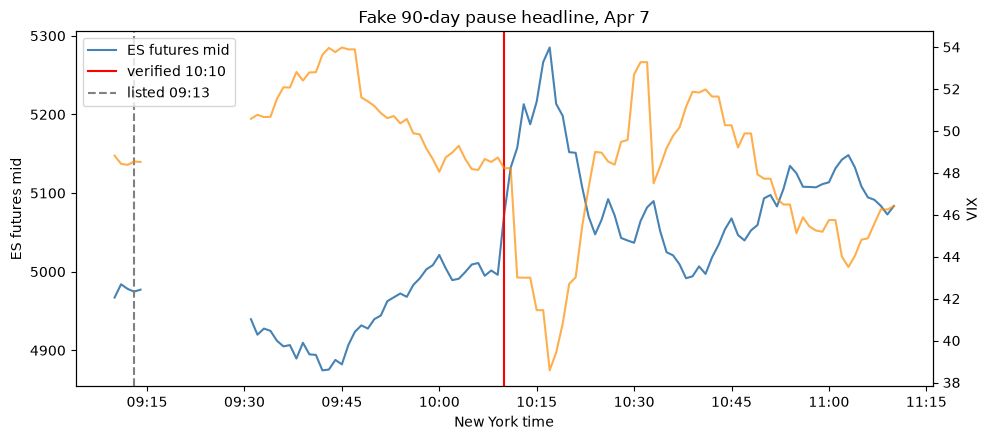

In [33]:
plot_event(9, "Fake 90-day pause headline, Apr 7", "chart_fake_pause.png")

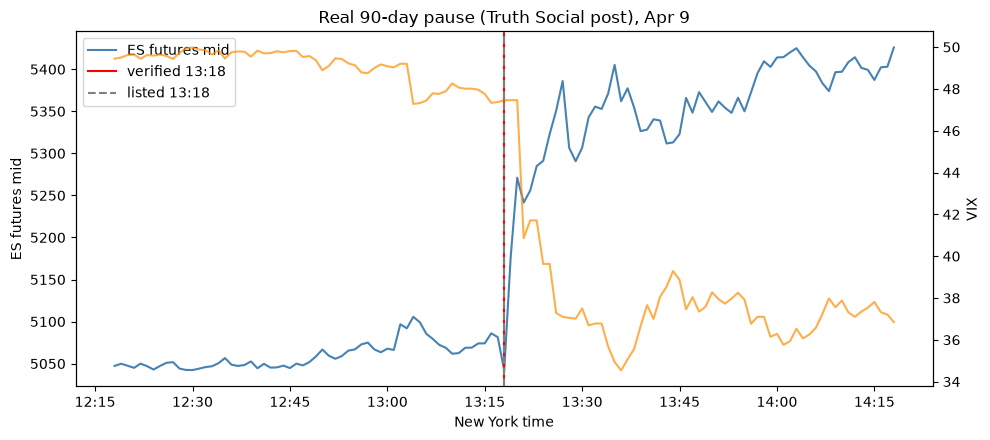

In [34]:
plot_event(20, "Real 90-day pause (Truth Social post), Apr 9", "chart_real_pause.png")

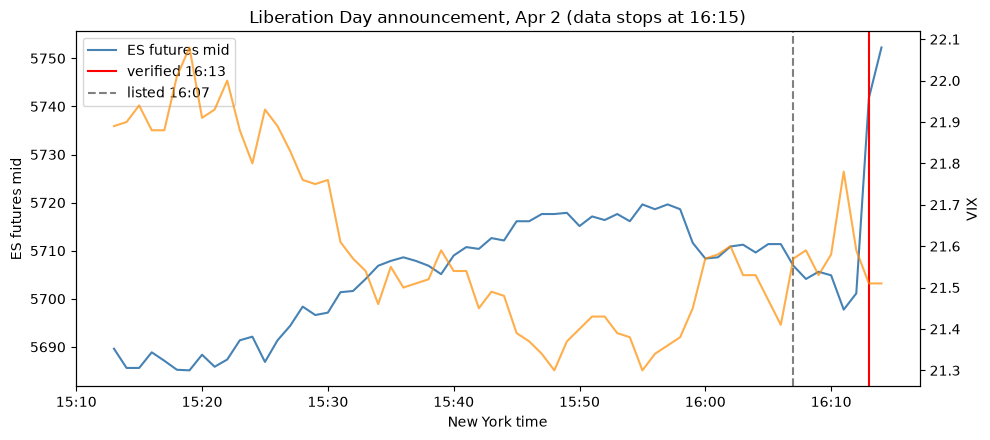

In [35]:
plot_event(1, "Liberation Day announcement, Apr 2 (data stops at 16:15)", "chart_liberation_day.png")

Our RTH data stops at 16:15 and ETH starts at 20:15, so the big after-hours fall on Apr 2 happens in the gap:

In [36]:
liberation_gap =\
    pd.Series({"last price 16:15": value_at(es_1min, pd.Timestamp("2025-04-02 16:15")),
               "first price 20:15": value_at(es_1min, pd.Timestamp("2025-04-02 20:16"))})

liberation_gap["change_%"] =\
    (liberation_gap["first price 20:15"] / liberation_gap["last price 16:15"] - 1) * 100

liberation_gap.round(2)

last price 16:15     5752.25
first price 20:15    5529.38
change_%               -3.87
dtype: float64

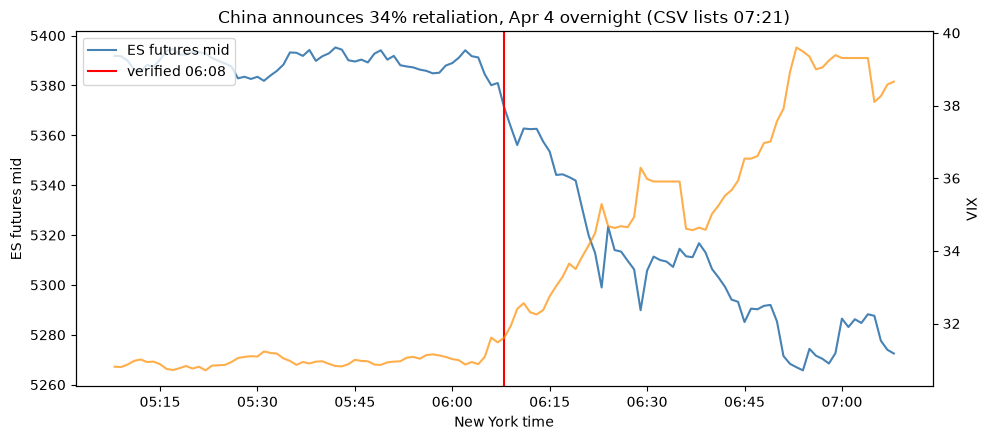

In [37]:
plot_event(6, "China announces 34% retaliation, Apr 4 overnight (CSV lists 07:21)", "chart_china_retaliation.png")